<h1>Loading the data<h1>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

path = r"C:\Users\rajpi\Desktop\Credit_Risk\data\credit_risk_dataset.csv"

df=pd.read_csv(path)

<h1>EDA<h1>

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.shape

(32581, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [6]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [7]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

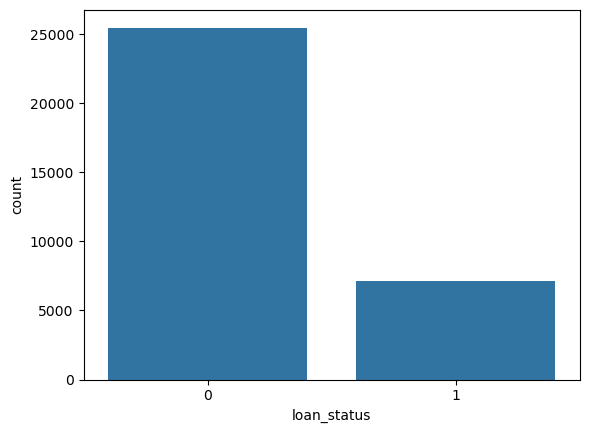

In [8]:
sns.countplot(x="loan_status",data=df)

In [9]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [10]:
num_cols=df.select_dtypes(include=np.number).columns
num_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

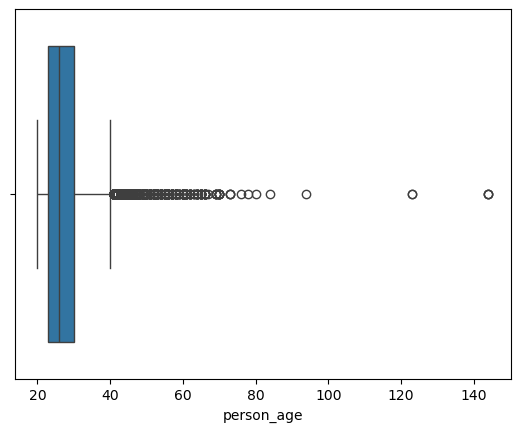

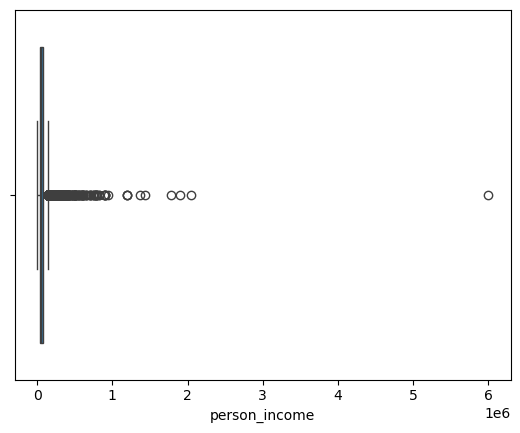

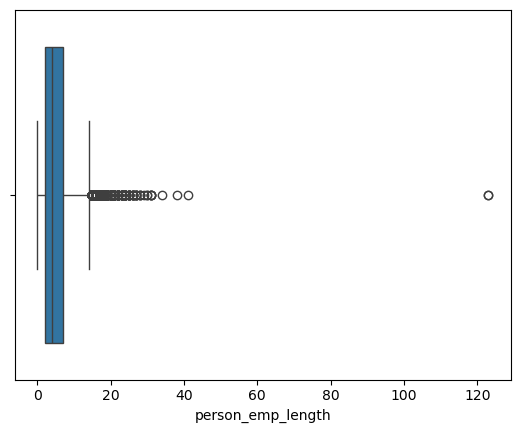

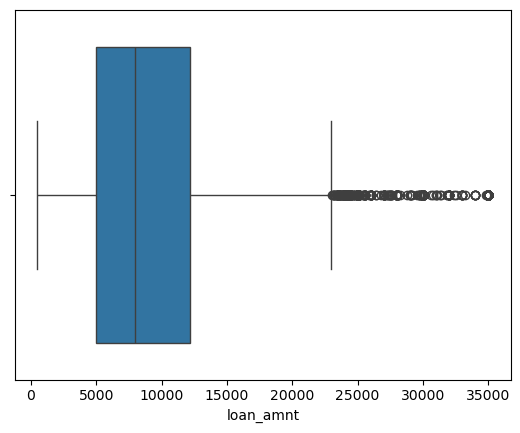

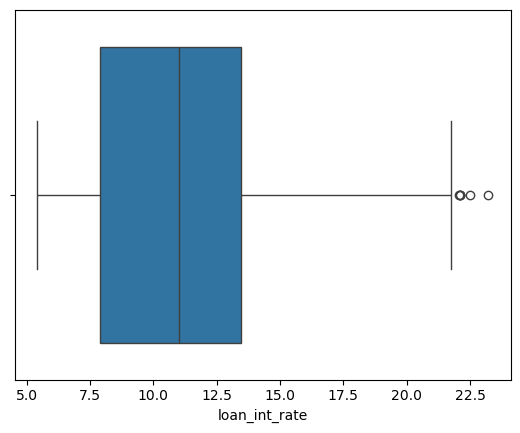

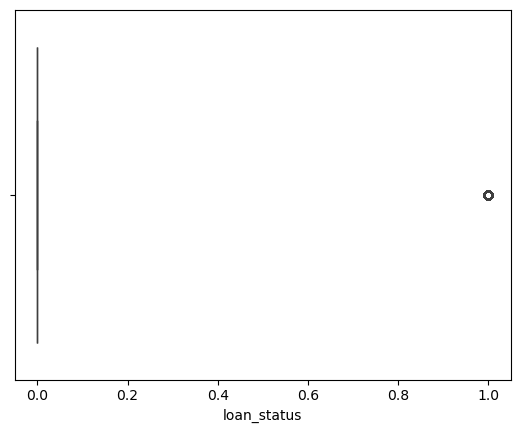

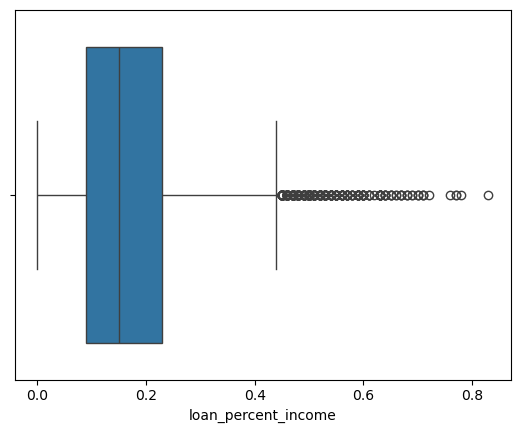

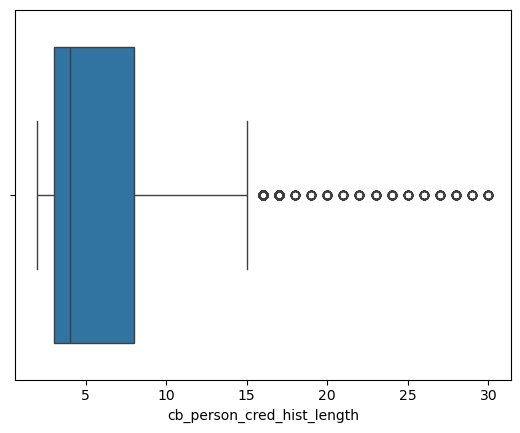

In [11]:
for i in num_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [12]:
(df["person_age"]>100).sum()

np.int64(5)

In [13]:
(df["person_emp_length"]>60).sum()

np.int64(2)

<Axes: >

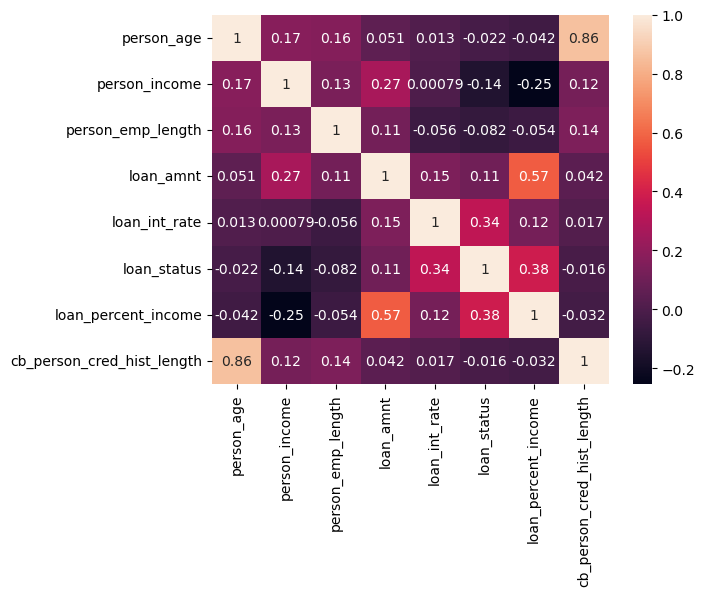

In [14]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

<h1>Data Cleaning<h1>

In [15]:
new_df=df.copy()

In [16]:
print(f"Original rows:{new_df.shape[0]}")
new_df.drop_duplicates(inplace=True)
print(f"Rows after deleting duplicate rows:{new_df.shape[0]}")

Original rows:32581
Rows after deleting duplicate rows:32416


In [17]:
new_df=new_df[(new_df["person_age"]>=18) & (new_df["person_age"]<=100)]

In [18]:
new_df=new_df[(new_df["person_emp_length"]<=new_df["person_age"]) & (new_df["person_emp_length"]<=60)]

In [19]:
X=new_df.drop("loan_status",axis=1)
y=new_df["loan_status"]

In [20]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [21]:
new_df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [22]:
num_cols=['person_age', 'person_income',
       'person_emp_length' ,'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']
cat_cols=['person_home_ownership',
       'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

<h1>Class Imbalance<h1>

In [23]:
zero,one=np.bincount(y_train)

In [24]:
print(zero,one)

19746 5471


In [25]:
scale_weights=zero/one
scale_weights

np.float64(3.6092122098336685)

<h1>Data Preprocessing<h1>

<h2>Preprocessing for Logistic regression<h2>

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])

<h2>Preprocessing for XGBoost<h2>

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])

<h1>Stratified Cross-Validation<h1>

<h2>Pipeline for Logistic regression<h2>

In [28]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

<h2>Pipeline for XGBoost<h2>

In [29]:
#XGboost Model
from xgboost import XGBClassifier
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weights,random_state=42
    ))
])

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [31]:
for cv_name, pipe in [("Logistic Regression", lr_pipeline),
                      ("XGBoost", xgb_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      print(f"Precision : {cv_results['test_precision'].mean()}")
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression
ROC-AUC : 0.8737232512074119
Accuracy : 0.814530375802201
Precision : 0.5513218395513471
Recall : 0.7795687561042799
F1 : 0.645855475462873

XGBoost
ROC-AUC : 0.9407667468408704
Accuracy : 0.9103779659873542
Precision : 0.7953353513434215
Recall : 0.7901700433247352
F1 : 0.7927258390037191



<h1>Models<h1>

<h2>1.Baseline Model:-Logistic Regression<h2>

In [32]:
lr_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [33]:
lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

<h2>2.XGBoost model<h2>

In [34]:
xgb_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [35]:
xgb_pipeline.fit(X_train, y_train)

c:\Users\rajpi\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:05:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

<h2>3.XGBoost Hyperparameter Tuning<h2>

In [36]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4),
    "classifier__colsample_bytree" :uniform(0.6,0.4),
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}

In [37]:
random_search = RandomizedSearchCV(
    xgb_pipeline,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


c:\Users\rajpi\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [13:11:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002A914990410>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000002A914956510>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x000002A9148BB4D0>},
                   scoring='average_precision', verbose=1)

In [38]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [39]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9119422205314272),
 'classifier__gamma': np.float64(1.1701084586672705),
 'classifier__learning_rate': np.float64(0.1080622171413546),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 9,
 'classifier__n_estimators': 360,
 'classifier__subsample': np.float64(0.8244436505339209)}

<h1>Evaluating models<h1>

In [40]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #Metrics
  accuracy     = accuracy_score(y_test, y_pred)
  precision    = precision_score(y_test, y_pred)
  recall       = recall_score(y_test, y_pred)
  f1           = f1_score(y_test, y_pred)
  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)


  print(f"{model_name} Metrics:")
  if threshold is not None:
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()


Logistic Regression Metrics:
Accuracy : 0.81
Precision : 0.54
Recall : 0.77
F1 : 0.63

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4969
           1       0.54      0.77      0.63      1336

    accuracy                           0.81      6305
   macro avg       0.73      0.79      0.75      6305
weighted avg       0.85      0.81      0.82      6305



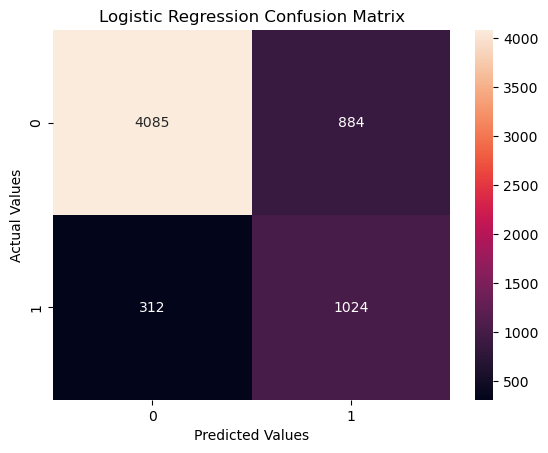

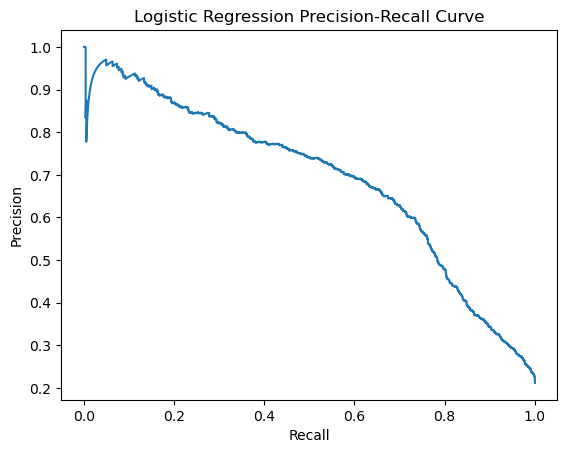

In [41]:
evaluate_model("Logistic Regression", lr_pipeline, X_test, y_test)

XG-Boost(Without Hyperparameter tuning) Metrics:
Accuracy : 0.90
Precision : 0.77
Recall : 0.77
F1 : 0.77

XG-Boost(Without Hyperparameter tuning) Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4969
           1       0.77      0.77      0.77      1336

    accuracy                           0.90      6305
   macro avg       0.85      0.86      0.85      6305
weighted avg       0.90      0.90      0.90      6305



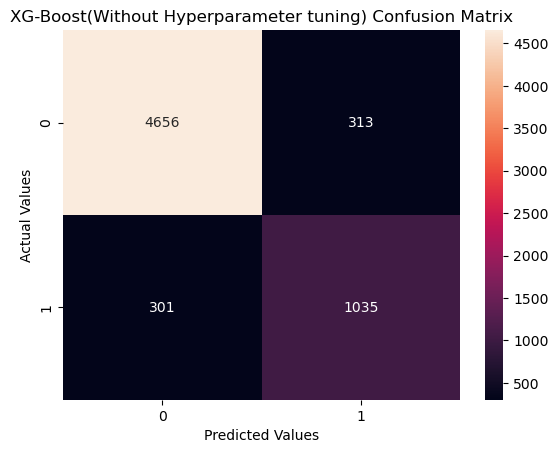

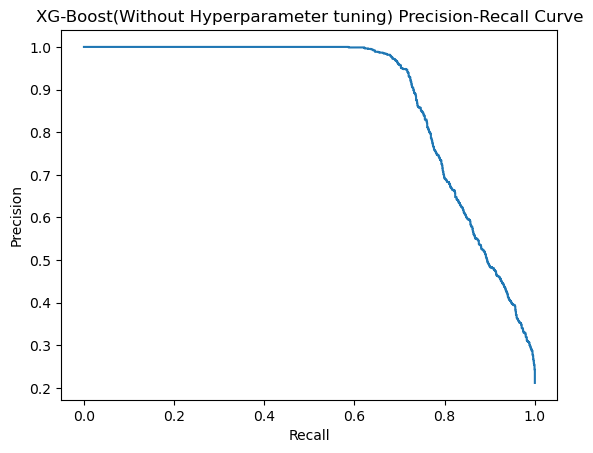

In [42]:
evaluate_model("XG-Boost(Without Hyperparameter tuning)", xgb_pipeline, X_test, y_test)

XG-Boost(With Hyperparameter Tuning) Metrics:
Accuracy : 0.91
Precision : 0.80
Recall : 0.80
F1 : 0.80

XG-Boost(With Hyperparameter Tuning) Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4969
           1       0.80      0.80      0.80      1336

    accuracy                           0.91      6305
   macro avg       0.87      0.87      0.87      6305
weighted avg       0.91      0.91      0.91      6305



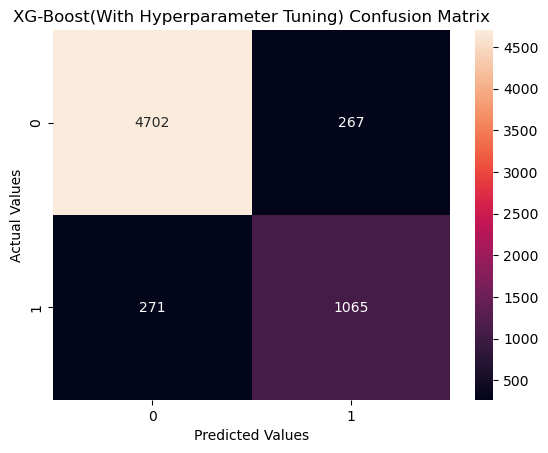

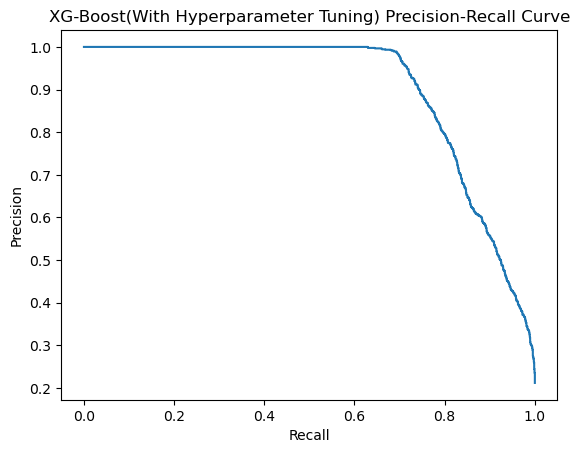

In [43]:
evaluate_model("XG-Boost(With Hyperparameter Tuning)", random_search, X_test, y_test)

<h1>Optimizing the Classification Threshold<h1>

Final Model Metrics:
Used Threshold : 0.71
Accuracy : 0.93
Precision : 0.95
Recall : 0.72
F1 : 0.82

Final Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4969
           1       0.95      0.72      0.82      1336

    accuracy                           0.93      6305
   macro avg       0.94      0.85      0.89      6305
weighted avg       0.93      0.93      0.93      6305



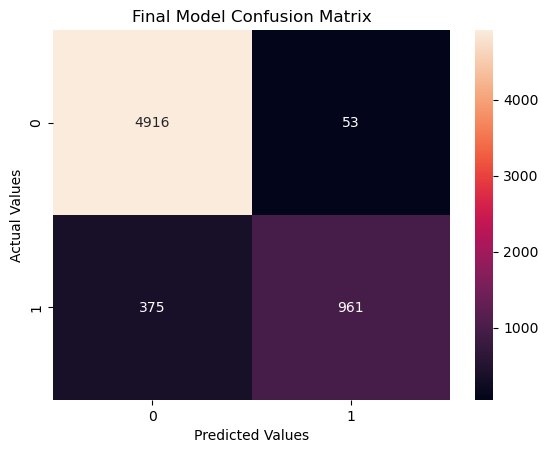

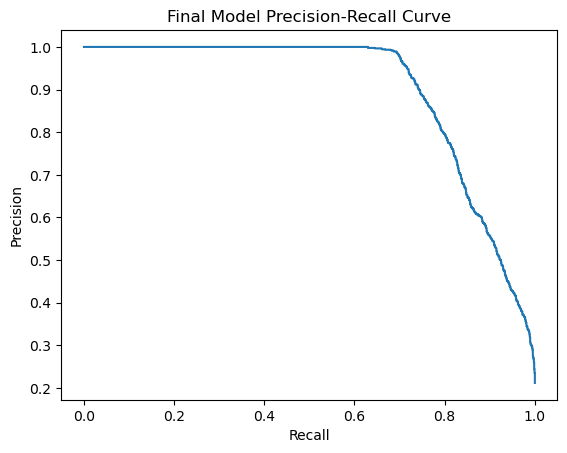

In [44]:
model=random_search.best_estimator_
prob = model.predict_proba(X_test)[:, 1]

precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions*recalls) / (precisions + recalls + 1e-9)

best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

evaluate_model("Final Model",model , X_test, y_test, best_threshold)

<h1>SHAP<h1>

In [46]:
import shap

In [47]:
xgb_classifier = xgb_pipeline.named_steps['classifier']

In [48]:
X_test_transformed = xgb_pipeline.named_steps['preprocessor'].transform(X_test)

In [49]:
feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()

In [50]:
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [51]:
X_test_df.head()

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,69996.0,5.0,7500.0,7.49,0.11,2.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,23.0,150000.0,3.0,5000.0,10.65,0.03,2.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,23.0,24000.0,5.0,7000.0,11.86,0.29,4.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,27.0,120000.0,11.0,7000.0,6.76,0.06,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,30.0,90000.0,7.0,4800.0,8.90,0.05,5.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [52]:
explainer = shap.TreeExplainer(xgb_classifier)

In [53]:
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-0.02505264, -0.4701158 , -0.1616563 , ..., -0.01054019,
        -0.00487685,  0.        ],
       [-0.08857795, -1.0461706 , -0.15017478, ..., -0.01276828,
        -0.00519376,  0.        ],
       [-0.00873504,  0.07109233, -0.07773729, ..., -0.0111782 ,
        -0.0097715 ,  0.        ],
       ...,
       [ 0.01878017, -1.0027747 , -0.08282451, ..., -0.01471892,
        -0.002004  ,  0.        ],
       [-0.01895009, -0.97678196,  0.02808329, ..., -0.01274502,
        -0.00496461,  0.        ],
       [ 0.0666575 ,  0.20250477,  0.07471231, ..., -0.00884608,
        -0.00105697,  0.        ]], dtype=float32)

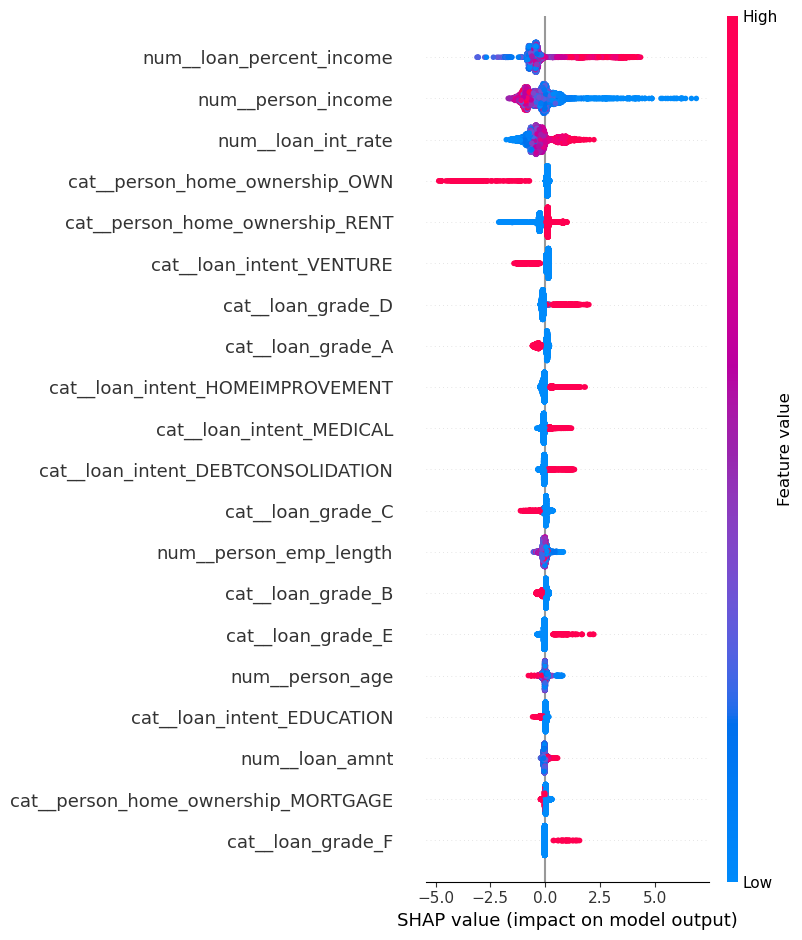

In [54]:
shap.summary_plot(shap_values, X_test_df)

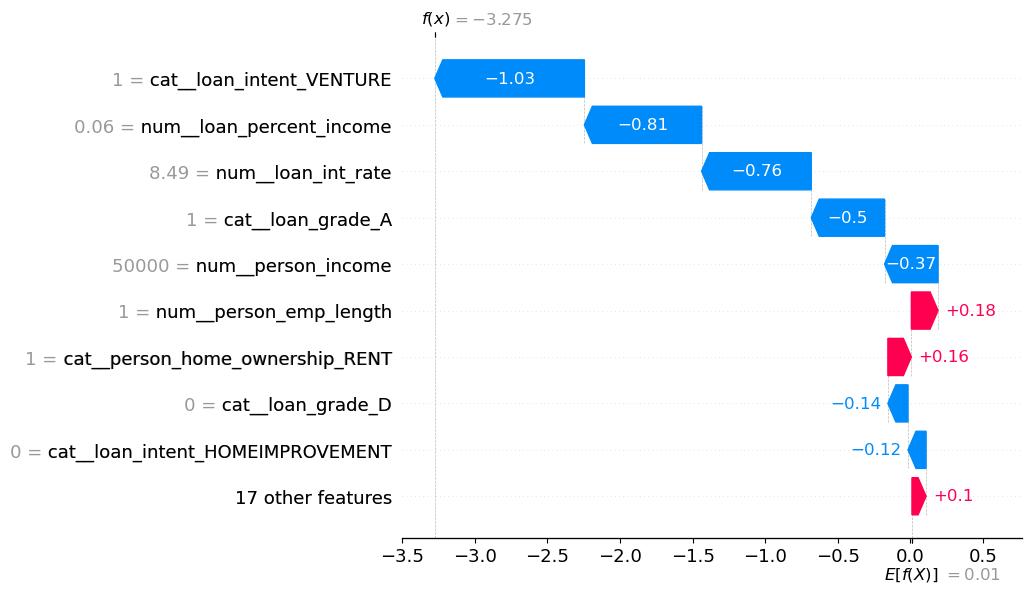

In [55]:
row_index = 5
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

<h1>False Positive and False Negatives<h1>

In [56]:
y_pred = random_search.predict(X_test)

In [57]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [58]:
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

In [59]:
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [60]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 267
False Negative : 271


<h1>Saving Final model and threshold

In [61]:
import joblib

In [62]:

import xgboost as xgb
best_pipeline = random_search.best_estimator_


my_preprocessor = best_pipeline.named_steps['preprocessor']
joblib.dump(my_preprocessor, "preprocess.pkl")


my_xgb_model = best_pipeline.named_steps['classifier']
my_xgb_model.save_model("model_final.json")

In [63]:
joblib.dump(best_threshold, "thresh_best.pkl")

['thresh_best.pkl']